In [83]:
from scripts.read_field import read_dir
from scripts.mm.experiment import Experiment
import os 
import numpy as np 
from typing import Literal
from scripts.scientific import apply
import matplotlib.pyplot as plt
apply()

In [96]:
path = os.path.join("./01-repulsion/skyrmion_system")
runs = [os.path.join(path, d) for d in os.listdir(path) if d.startswith("drive-")]
data = [read_dir(run) for run in runs]
experiments = [Experiment.load(run) for run in runs]

In [97]:
def trajectory(data, experiment: Experiment, method: Literal['center', 'charge'] = 'center'):
    xs = np.array([])
    ys = np.array([])
    W = experiment.width / experiment.dx
    H = experiment.height / experiment.dx
    X, Y = np.meshgrid(np.arange(-W, W) * experiment.dx, -np.arange(-H, H) * experiment.dx)
    for i in range(len(data)):
        if method == 'center':
            weight = (1- data[i,:,:,2]) ** 2
        if method == 'charge':
            weight = np.sum(data[i] * np.linalg.cross(np.gradient(data[i], axis=0), np.gradient(data[i], axis=1)), axis=2)
        norm = np.sum(weight)

        x = np.sum(weight * X) / norm
        y = np.sum(weight * Y) / norm
        xs = np.append(xs, x)
        ys = np.append(ys, y)
    return xs, ys

[np.float64(-0.012500000000000271), np.float64(-0.08844755937712628), np.float64(-0.05669482997448532), np.float64(-0.06461548677277063), np.float64(-0.051510797059429805), np.float64(-0.05619005308907423), np.float64(-0.05499841112295687), np.float64(-0.04680202599602856), np.float64(-0.03404493721400785), np.float64(-0.02998619589831), np.float64(-0.02901612867458856), np.float64(-0.04151612867458883), np.float64(-0.10247270192919519), np.float64(-0.052982145190878085), np.float64(-0.0392983463152053), np.float64(-0.028664911178216488), np.float64(-0.010155473184335004), np.float64(0.0020823839581255756), np.float64(0.032309537608633636), np.float64(0.044568925607148265), np.float64(0.07273869697744748), np.float64(0.08164434556145372), np.float64(0.06914434556145346), np.float64(0.005838341019437268), np.float64(0.13226756790416028), np.float64(0.157027265525691), np.float64(0.17316635468478472), np.float64(0.24564463361213532), np.float64(0.2656683179968983), np.float64(0.327146473

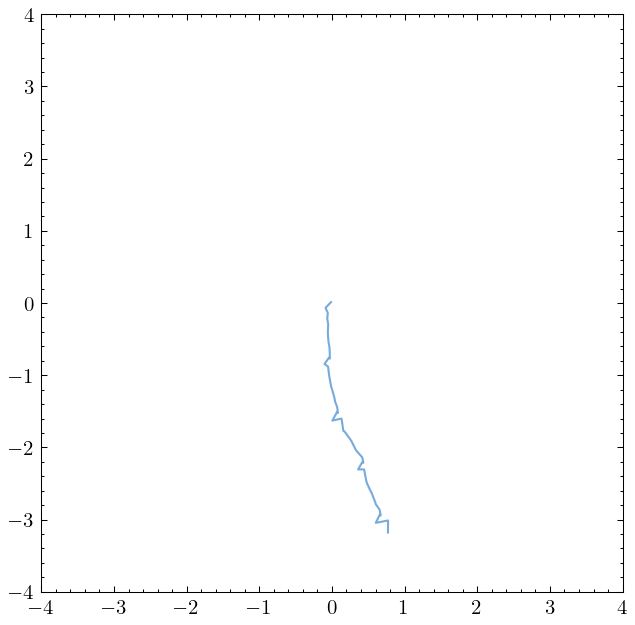

In [99]:
ts = [trajectory(d, e, method='center') for d, e in zip(data, experiments)]
xs, ys = [], []
curr = [np.float64(0), np.float64(0)]

for t in ts:
    xs = [*xs, *(t[0] + curr[0])]
    ys = [*ys, *(t[1] + curr[1])]
    curr[0] = xs[-1]
    curr[1] = ys[-1]

plt.subplots(figsize=(5,5))
plt.plot(xs, ys)
plt.xlim([-4,4])
plt.ylim([-4,4])

print(xs, ys)

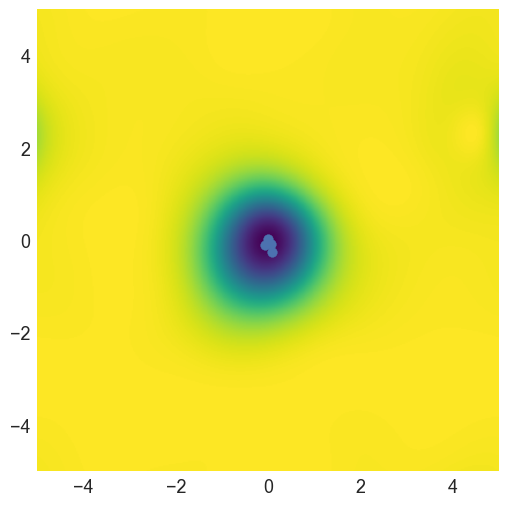

In [78]:
plt.imshow(data[3][1,:,:,2], extent=([-5, 5, -5, 5]))
plt.scatter(*ts[3])